# Confidence Intervals

Simulate confidence intervals for either repeated small-scale experiments versus
single-shot large-scale experiments.

First, we'll need some helper functions to compute standard error for each row
in a matrix, as well as compute a CI.

$$SE = \frac{\sigma}{\sqrt n}$$
$$CI_\alpha = \mu \pm (SE \cdot \Phi^{-1}(1 - \frac{\alpha}{2}))$$

Note that $\alpha$ describes the level of confidence ($\alpha = .05$ for a 95%
CI), and $\Phi^{-1}(q)$ is the inverse cumulative distribution function for the
normal distribution. It is called `qnorm()` in R.


In [96]:
library("dplyr")
library("ggplot2")

rowSE <- function(mat) {
  vapply(
    X = seq(nrow(mat)),
    FUN = function(i,m,n) {sd(m[i,]) / sqrt(n)},
    FUN.VALUE = numeric(1),
    m = mat,
    n = ncol(mat)
  )
}

rowCI <- function(m, se, alpha = .05) {
  crit <- qnorm(1 - (alpha / 2))
  matrix(
    c(m - (se * crit), m + (se * crit)),
    ncol = 2
  )
}


Now we can simulate some data! For the small experiments, there will be `k`
experiments each with `n` subjects (a total of `N` subjects). For the large
experiment, there will be `N` subjects.

In [97]:
n <- 10
k <- 25
N <- n * k
sd <- 1
d <- .3
alpha <- .05
crit <- qnorm(1 - (alpha / 2))

mat <- matrix(
  rnorm(N, sd*d, sd),
  nrow = k,
  ncol = n
)
se_rep <- rowSE(mat)
mu_rep <- rowMeans(mat)
ci_rep <- rowCI(mu_rep, se_rep)

big <- rnorm(N, sd*d, sd)
se_big <- sd(big) / sqrt(N)
mu_big <- mean(big)
ci_big <- matrix(
  c(mu_big - se_big * crit, mu_big + se_big * crit),
  nrow = 1
)


words!

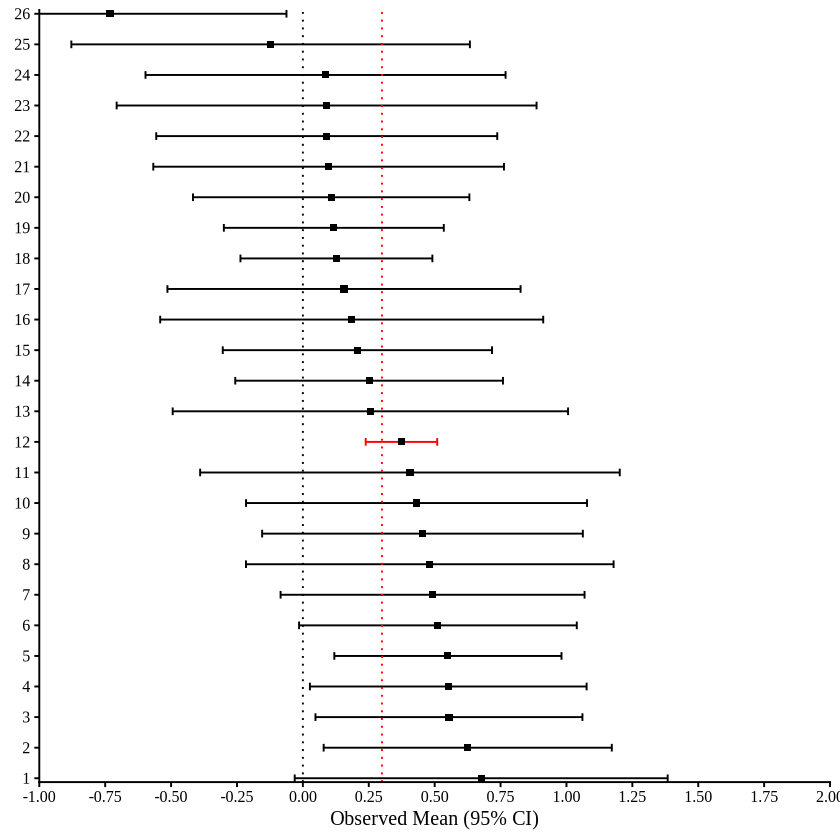

In [107]:
ci <- rbind(ci_rep, ci_big) 
dat <- as_tibble(ci) |>
  mutate(
    mu = c(mu_rep, mu_big),
    type = c(rep("small", k), "large")
  ) |>
  arrange(-mu) |>
  mutate(study = as.factor(seq(k+1)))
names(dat) <- c("lo", "hi", "mu", "type", "study")

(g1 <- dat |>
  ggplot(aes(x = mu, y = study)) +
  geom_errorbar(aes(xmin = lo, xmax = hi, color = type), orientation = "y", width = 0.25) +
  geom_point(, shape = 15) +
  geom_vline(xintercept = 0, color = "black", linetype = "dotted") +
  geom_vline(xintercept = d, color = "red", linetype = "dotted") +
  coord_cartesian(xlim = c(-1, 2), expand = FALSE) +
  scale_x_continuous(breaks = seq(from=-1, to=2, by=.25)) +
  scale_size_area(max_size = 3, guide = "none") +
  scale_color_manual(values = c("red", "black")) +
  labs(x = "Observed Mean (95% CI)", y = NULL) +
  theme_classic(base_size = 12, base_family = "serif")) +
  theme(legend.position="none")
ggsave("ci.png", g1, width = 4, height = 8, units = "in", dpi = 300)

[[ci.png]]

The snake plot above shows two things.

1. As a 95% CI predicts, 95% (about 19/20) of the produced confidence intervals
contain the true mean (`d`).

2. The power of each individual study is poor. With only 10 observations per
experiment, only 1/20 experiments fails to reject the null.
